**SAPIANS** · SCC5819 · MÓDULO 00 — A BASE SRAG · COMPARAÇÃO DE BALANCEAMENTO

# Balanceamento sob parâmetros fixos — comparação histórica

O [modelo do curso](../srag_model_walkthrough.ipynb) fornece a referência.
Este caderno compara estratégias de balanceamento mantendo a separação temporal,
as variáveis e a configuração do modelo. A pergunta inclui tanto a ordenação dos
riscos quanto a qualidade das probabilidades previstas.

A execução padrão lê o registro commitado em
[`gold/balance_comparison.json`](../../gold/balance_comparison.json).
A opção `RUN_REFIT` refaz o estudo com o mesmo protocolo; ela não substitui
automaticamente o registro nem o modelo adotado pelo curso.

[README do módulo](../../README.md) · [seleção do modelo](../srag_selection_walkthrough.ipynb) ·
[`MODEL.md`](../../MODEL.md) · [`GOLD.md`](../../GOLD.md) ·
[núcleo reproduzível](../../../../tools/srag_61_balance.py)

---

**Objetivos.** Conferir a preservação dos conjuntos de avaliação; comparar todas
as execuções; auditar as propostas sintéticas; interpretar discriminação,
calibração e incerteza sem escolher configurações pelo teste.

**Estado e rota.** Comparação concluída com parâmetros fixos, distinta da busca
posterior com ajuste por estratégia. §§1–2 treino e métricas; §3 auditoria
sintética; §4 calibração; §5 diferenças pareadas; §6 síntese. A unidade é a
notificação, e o teste já observado é exploratório. O modo padrão lê o agregado;
`RUN_REFIT` permanece uma opção explícita, sem adoção automática de modelo.


In [1]:
%pip install -q numpy pandas pyarrow scipy scikit-learn xgboost matplotlib imbalanced-learn sklearn-compat
# Versões reproduzíveis em requirements.lock; sem atualização do ambiente preparado.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import hashlib
import importlib.metadata
import io
import json
import os
import pathlib
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if os.environ.get("INTERPRETABLE_ML_REPO"):
    REPO = pathlib.Path(os.environ["INTERPRETABLE_ML_REPO"]).resolve()
else:
    REPO = pathlib.Path.cwd().resolve()
    while REPO != REPO.parent and not (REPO / "tools/srag_61_balance.py").exists():
        REPO = REPO.parent
if not (REPO / "tools/srag_61_balance.py").exists():
    raise RuntimeError(
        "Abra o caderno no repositório ou configure INTERPRETABLE_ML_REPO."
    )

sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_61_balance as B

# Figuras e um eventual refit ficam fora da árvore versionada.
work_env = os.environ.get("INTERPRETABLE_ML_WORK")
WORK = (
    pathlib.Path(work_env).resolve()
    if work_env
    else pathlib.Path(tempfile.mkdtemp(prefix="srag_balance_comparison-"))
)
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
SP.aplicar(tema="global")
pd.set_option("display.width", 160)

RANDOM_STATE = 42
RUN_REFIT = False
SNAPSHOT = REPO / "modules/00-dataset/gold/balance_comparison.json"
if not SNAPSHOT.exists():
    raise RuntimeError("O registro commitado do estudo não foi encontrado.")
E = json.loads(SNAPSHOT.read_text(encoding="utf-8"))
if RUN_REFIT:
    # O refit reproduz o protocolo; os avisos continuam visíveis, mas não há
    # impressão intermediária de métricas com formatação diferente da aula.
    with contextlib.redirect_stdout(io.StringIO()):
        E = B.run_study(pathlib.Path.cwd() / "figures_generated/balance_comparison")
    print("Refit concluído; as próximas células usam as medidas desta execução.")
else:
    print(
        "Fonte das medidas: registro commitado do estudo; nenhum modelo foi retreinado."
    )

NOMES = {
    "atual": "Atual",
    "pesos": "Pesos de classe",
    "reducao": "Redução da majoritária",
    "smotenc_restrito": "SMOTENC com restrições",
}
ORDEM = list(NOMES)
CORES = {
    "atual": SP.ESCURO,
    "pesos": SP.CINZA,
    "reducao": SP.CINZA_CLARO,
    "smotenc_restrito": SP.CINZA,
}
MARCADORES = {"atual": "o", "pesos": "^", "reducao": "s", "smotenc_restrito": "D"}
TRACOS = {"atual": "-", "pesos": "--", "reducao": "-.", "smotenc_restrito": ":"}
JANELAS = {"val": "Validação", "test": "Teste exploratório"}


def ident(run):
    return {"estratégia": NOMES[run["method"]], "semente": int(run["seed"])}


linhas = [
    {**ident(r), "método": r["method"], "conjunto": s, **r[s]}
    for r in E["runs"]
    for s in JANELAS
]
placar = pd.DataFrame(linhas)
gold = M.load_gold()
assert (
    E["dataset"]["sample_sha256"] == hashlib.sha256(M.AMOSTRA.read_bytes()).hexdigest()
)
assert E["dataset"]["features"] == list(M.FEATURES)
assert E["protocol"]["xgb_params"] == M.XGB_PARAMS
for split in ("train", "val", "test"):
    observed = gold.loc[gold["split"] == split, "y_obito"]
    saved = E["dataset"]["train_original" if split == "train" else split]
    assert len(observed) == saved["n"]
    assert int(observed.sum()) == saved["positivos"]
print("Amostra, variáveis, configuração e contagens conferem com as fontes canônicas.")

print("Apresentação: SAPIANS Global · fonte:", SP.FONTE_ATUAL)


Fonte das medidas: registro commitado do estudo; nenhum modelo foi retreinado.
Amostra, variáveis, configuração e contagens conferem com as fontes canônicas.
Apresentação: SAPIANS Global · fonte: Satoshi


## §1 — O que mudou no treino e o que permaneceu fixo

As estratégias alteram o material ou o peso usado para ajustar o modelo. Todas
são avaliadas nos mesmos registros reais de validação e teste, sem reamostrar
esses conjuntos. A prevalência observada em cada janela continua sendo a
referência para interpretar as probabilidades.

O teste já havia sido consultado no desenvolvimento anterior: seus resultados
são uma comparação exploratória, sem a pretensão de avaliação prospectiva nova.
Os hiperparâmetros do modelo permanecem os do curso; este estudo não realiza
uma busca própria para favorecer qualquer estratégia.


In [3]:
print("Protocolo registrado")
for key in ("sampling_ratio", "probabilities", "primary", "test_status", "smotenc"):
    print(f"{key}: {E['protocol'][key]}")
print(f"Semente do modelo: {SP.pt_int(E['protocol']['model_seed'])}")
print("Sementes dos amostradores: " + ", ".join(SP.pt_int(s) for s in E["protocol"]["sampler_seeds"]))
print(f"Execuções registradas: {SP.pt_int(len(E['runs']))}")
print(f"Repetições do bootstrap: {SP.pt_int(E['protocol']['bootstrap_repeats'])}")
print(f"Semente do bootstrap: {SP.pt_int(E['protocol']['bootstrap_seed'])}")
print(f"Intervalo percentil do bootstrap: {SP.pct(1 - 2 * 0.025, 0)}")
print(f"Limiar diagnóstico: {SP.pt(E['protocol']['threshold_diagnostic'], 2)}")
print(f"Variáveis de entrada: {SP.pt_int(len(E['dataset']['features']))}")
print("SHA-256 da amostra: " + E["dataset"]["sample_sha256"])
print("\nConfiguração fixa do XGBoost")
print(SP.tabela(pd.DataFrame([E["protocol"]["xgb_params"]]), 4))

versoes = pd.DataFrame([
    {"pacote": package, "registro": version,
     "ambiente": importlib.metadata.version(package)}
    for package, version in E["protocol"]["versions"].items()
])
print("\nVersões registradas e ambiente atual")
print(SP.tabela(versoes))
print("Python do ambiente: " + sys.version.split()[0])
print("Versões de pacotes conferem? " + str(bool((versoes.registro == versoes.ambiente).all())))

janelas = []
for split in ("train", "val", "test"):
    sub = gold[gold["split"] == split]
    saved = E["dataset"]["train_original" if split == "train" else split]
    janelas.append({"conjunto": split,
                    "anos": f"{int(sub.ano_onset.min())}–{int(sub.ano_onset.max())}",
                    "registros": saved["n"], "óbitos": saved["positivos"],
                    "sobrevidas": saved["negativos"], "proporção de óbitos": saved["prev"]})
print("\nJanelas originais; validação e teste não recebem reamostragem")
print(SP.tabela(pd.DataFrame(janelas), {"proporção de óbitos": 6}))

treinos = pd.DataFrame([{**ident(r), **r["train"]} for r in E["runs"]])
print("\nMaterial efetivamente usado em cada treino")
print(SP.tabela(treinos, {"prev": 6, "effective_positive_weight": 6}))


Protocolo registrado
sampling_ratio: 1:1
probabilities: raw; no recalibrator fitted
primary: Brier/log-loss, calibration; AUC/AP secondary
test_status: 2024 exploratory; already observed
smotenc: calendar reconstruction and synthetic-only rejection; anchor gate audit
Semente do modelo: 42
Sementes dos amostradores: 42, 43, 44
Execuções registradas: 8
Repetições do bootstrap: 500
Semente do bootstrap: 42
Intervalo percentil do bootstrap: 95%
Limiar diagnóstico: 0,50
Variáveis de entrada: 40
SHA-256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918

Configuração fixa do XGBoost
n_estimators max_depth learning_rate min_child_weight reg_lambda tree_method  enable_categorical eval_metric random_state n_jobs
         800         4        0,0500              100     5,0000        hist                True         auc           42     -1

Versões registradas e ambiente atual
          pacote registro ambiente
           numpy    2.4.6    2.4.6
          pandas    2.3.

**O que olhar.**

- Pesos de classe preservam os registros e mudam a penalização dos erros no ajuste.
- A redução retém uma parte dos registros reais da classe majoritária.
- O braço sintético preserva os originais e acrescenta propostas aceitas pela auditoria.
- A proporção balanceada do treino não substitui a proporção real dos conjuntos de avaliação.


## §2 — Comparar probabilidades, ordenação e decisões

Brier e log-loss avaliam as probabilidades individuais: valores menores são
melhores. AUC avalia ordenação entre classes; average precision (AP) resume
a curva precisão–revocação e depende da prevalência da população avaliada.
Valores maiores de AUC e AP são melhores.

A tabela de decisões usa somente o limiar diagnóstico registrado. Ela mostra
um possível compromisso entre detectar óbitos e disparar alertas, sem definir
um limiar clínico recomendado. As probabilidades são brutas, sem recalibração.


In [4]:
colunas_prob = ["estratégia", "semente", "conjunto", "brier", "logloss", "auc", "ap",
                "mean_pred", "observed", "gap"]
print("Todas as execuções: probabilidades e discriminação")
print(SP.tabela(placar[colunas_prob], 6))
colunas_decisao = ["estratégia", "semente", "conjunto", "sensitivity", "specificity",
                  "ppv", "alert_rate", "tp", "fp", "tn", "fn"]
print("\nTodas as execuções: decisões no limiar registrado")
print(SP.tabela(placar[colunas_decisao], 6))
print("\nTP: óbito com alerta; FP: sobrevida com alerta; TN: sobrevida sem alerta; FN: óbito sem alerta.")


Todas as execuções: probabilidades e discriminação
            estratégia semente conjunto    brier  logloss      auc       ap mean_pred observed      gap
                 Atual      42      val 0,135617 0,420903 0,756427 0,381674  0,220948 0,189332 0,031616
                 Atual      42     test 0,130808 0,409020 0,764448 0,388790  0,215373 0,182443 0,032929
       Pesos de classe      42      val 0,163705 0,489156 0,754901 0,378300  0,346045 0,189332 0,156712
       Pesos de classe      42     test 0,159105 0,478040 0,763973 0,390181  0,339275 0,182443 0,156831
Redução da majoritária      42      val 0,169037 0,501612 0,754081 0,378503  0,359307 0,189332 0,169975
Redução da majoritária      42     test 0,163461 0,488382 0,761704 0,385988  0,349120 0,182443 0,166676
Redução da majoritária      43      val 0,171958 0,508375 0,754096 0,376645  0,366299 0,189332 0,176967
Redução da majoritária      43     test 0,166391 0,495141 0,762886 0,390558  0,357309 0,182443 0,174866
Redução da ma

figura: figures_generated/balanceamento_brier_execucoes.png


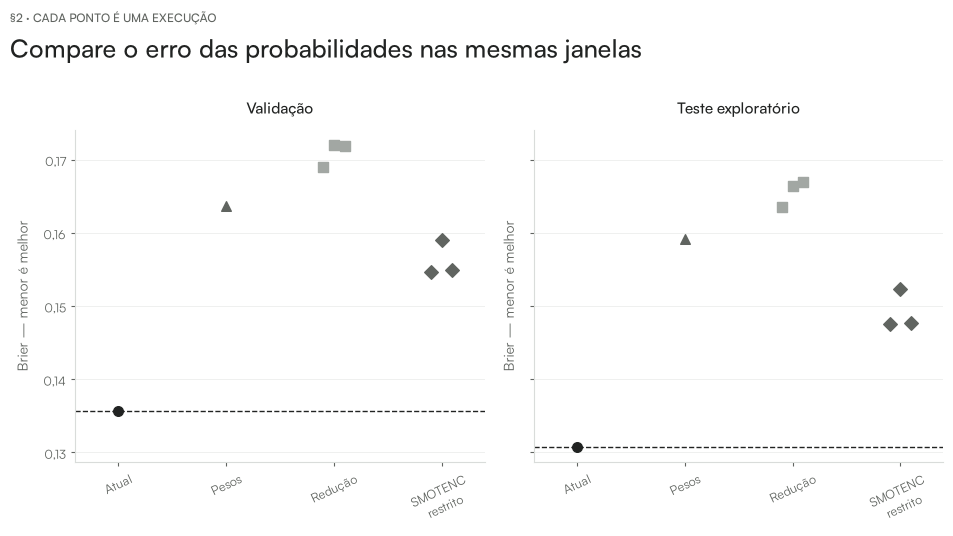

In [5]:
fig, axes = plt.subplots(1, 2, figsize=SP.SLOT, sharey=True)
for ax, split in zip(axes, JANELAS):
    for position, method in enumerate(ORDEM):
        values = placar.loc[
            (placar["método"] == method) & (placar["conjunto"] == split), "brier"
        ].to_numpy()
        offset = (
            np.linspace(-0.10, 0.10, len(values))
            if len(values) > 1
            else np.array([0.0])
        )
        ax.scatter(
            position + offset,
            values,
            color=CORES[method],
            marker=MARCADORES[method],
            s=48,
            zorder=3,
        )
    reference = float(
        placar.loc[
            (placar["método"] == "atual") & (placar["conjunto"] == split), "brier"
        ].iloc[0]
    )
    ax.axhline(reference, color=SP.ESCURO, linestyle="--", linewidth=1)
    ax.set_title(JANELAS[split])
    ax.set_xticks(
        range(len(ORDEM)),
        ["Atual", "Pesos", "Redução", "SMOTENC\nrestrito"],
        rotation=25,
    )
    ax.set_ylabel("Brier — menor é melhor")
    ax.set_xlim(-0.4, len(ORDEM) - 0.6)
SP.titulo(
    fig,
    "Compare o erro das probabilidades nas mesmas janelas",
    "§2 · cada ponto é uma execução",
)
_ = SP.salvar(fig, "balanceamento_brier_execucoes")
plt.show()


**O que olhar.**

- Compare cada ponto com a referência da própria janela, e não com o treino balanceado.
- Maior sensibilidade pode acompanhar mais falsos alertas e probabilidades superestimadas.
- Diferenças entre sementes descrevem a sensibilidade ao amostrador; não são um intervalo de incerteza populacional.


## §3 — Que registros sintéticos foram aceitos e rejeitados?

O braço estudado é **SMOTENC com restrições**, não uma execução inalterada
da biblioteca. A idade e o instante de início são padronizados para a busca
de vizinhos; as categorias são tratadas como categorias. O calendário é
reconstruído e somente as propostas sintéticas são submetidas aos filtros.

O metadado do portão da coorte vem da ficha âncora para auditoria, não entra
nas variáveis preditoras e não é interpolado. A aceitação pelos filtros
verifica regras explícitas do estudo; não comprova plausibilidade clínica
completa. As anomalias que já existiam nos originais são preservadas e contadas.
Uma proposta pode infringir mais de uma regra, de modo que a soma por regra
pode ultrapassar o total de propostas rejeitadas.


In [6]:
resumos, regras, intersecoes, anos, portoes, originais, escalas = [], [], [], [], [], [], []
for run in E["runs"]:
    a = run["audit"]
    if run["method"] == "reducao":
        print(f"Redução, semente {SP.pt_int(run['seed'])}: SHA-256 dos IDs retidos = {a['hash_ids_retidos']}")
        retained = pd.DataFrame([{"ano": year, "retidos": n} for year, n in sorted(a["retidos_por_ano"].items())])
        print(SP.tabela(retained, cru=("ano",)))
    if run["method"] != "smotenc_restrito":
        continue
    keys = ("n_proposto", "n_rejeitado", "n_aceito", "n_usado", "quota_desejada", "quota_atingida", "originais_preservados")
    resumos.append({"semente": run["seed"], **{k: a[k] for k in keys}})
    regras.extend({"semente": run["seed"], "regra": k, "propostas rejeitadas": v}
                  for k, v in a["rejeicoes_por_regra"].items())
    originais.extend({"semente": run["seed"], "regra": k, "originais com anomalia": v}
                     for k, v in a["anomalias_originais"].items())
    print(f"\nSMOTENC, semente {SP.pt_int(run['seed'])}: {a['metadado_portao']}")
    print("Ordem das regras no padrão de interseção: " + " | ".join(a["ordem_regras_intersecoes"]))
    print("Variáveis fornecidas ao amostrador: " + ", ".join(a["sampler_features"]))
    intersecoes.extend({"semente": run["seed"], "padrão de regras": k, "propostas": v}
                      for k, v in sorted(a["intersecoes"].items()))
    for year, values in sorted(a["rejeicoes_por_ano"].items()):
        anos.append({"semente": run["seed"], "ano": year, **values})
    for gate, values in sorted(a["rejeicoes_por_portao_ancora"].items()):
        portoes.append({"semente": run["seed"], "portão da âncora": gate, **values})
    for feature, mean, scale in zip(("idade_anos", "onset_day"), a["scaler_mean"], a["scaler_scale"]):
        escalas.append({"semente": run["seed"], "variável": feature, "média do treino": mean, "escala do treino": scale})
    assert a["n_proposto"] == a["n_aceito"] + a["n_rejeitado"]
    assert a["n_usado"] <= a["n_aceito"]
    assert a["originais_preservados"]

for title, rows in (("Propostas, rejeições, quota e uso", resumos),
                    ("Rejeições por regra — contagens podem se sobrepor", regras),
                    ("Interseções — cada padrão conta propostas distintas", intersecoes),
                    ("Rejeição por ano de início reconstruído", anos),
                    ("Rejeição por portão da âncora", portoes),
                    ("Anomalias originais preservadas", originais),
                    ("Transformação numérica ajustada apenas no treino", escalas)):
    print("\n" + title)
    print(SP.tabela(pd.DataFrame(rows), 6, cru=("ano", "padrão de regras")))


Redução, semente 42: SHA-256 dos IDs retidos = d449d630665ac2fc2db72a4229214530fc9c47f8017c475eac4306fe67154c57
 ano retidos
2020  41.438
2021  72.869
2022  11.131
Redução, semente 43: SHA-256 dos IDs retidos = 3f4896bffe5ace5196376b7e51eda787b09115f94e3aa6cbf0e5ed45f122543f
 ano retidos
2020  41.596
2021  72.788
2022  11.054
Redução, semente 44: SHA-256 dos IDs retidos = 72cc7ba232231d31921c9538f2ab5af7c079aeda434dfee7d90b464fcf0f5762
 ano retidos
2020  41.341
2021  72.933
2022  11.164

SMOTENC, semente 42: herdado da ancora; apenas auditoria
Ordem das regras no padrão de interseção: portao | pre_campanha | fora_coorte | dominio_idade | dominio_categorias | dominio_dose
Variáveis fornecidas ao amostrador: idade_anos, onset_day, cs_sexo, cs_raca, cs_escol_n, cs_zona, cs_gestant, puerpera, cardiopati, hematologi, sind_down, hepatica, asma, diabetes, neurologic, pneumopati, imunodepre, renal, obesidade, out_morbi, febre, tosse, garganta, dispneia, desc_resp, saturacao, diarreia, vomito, 

**O que olhar.**

- Distingua propostas geradas, propostas válidas e propostas efetivamente usadas.
- A reconstrução do calendário e os filtros definem uma estratégia específica, cuja auditoria precisa acompanhar o resultado.
- A rejeição desigual entre anos ou grupos pode alterar a composição do material sintético aceito.


## §4 — As probabilidades correspondem às frequências observadas?

Cada faixa reúne previsões parecidas e compara a probabilidade média com a
proporção de óbitos realmente observada. Na diagonal, essas grandezas
coincidem. Pontos abaixo dela indicam superestimação naquela faixa; pontos
acima indicam subestimação. As faixas são fixas e os intervalos de Wilson
descrevem a frequência observada dentro de cada faixa.

O intercepto de calibração com inclinação fixa mede um deslocamento global
das probabilidades na escala logit. O ajuste conjunto de intercepto e
inclinação avalia também a amplitude das previsões. São regressões
**diagnósticas**, calculadas nos rótulos de avaliação; nenhum coeficiente
é aplicado às probabilidades. Um intercepto ideal é nulo e uma inclinação
ideal é unitária.


In [7]:
cal_cols = ["estratégia", "semente", "conjunto", "mean_pred", "observed", "gap",
            "cal_intercept", "cal_intercept_joint", "cal_slope", "clipped_probabilities"]
print("Diagnósticos de calibração — todas as probabilidades continuam brutas")
print(SP.tabela(placar[cal_cols], 6))
print(f"Referência diagnóstica: intercepto {SP.pt(0, 1)}; inclinação {SP.pt(1, 1)}.")
print("cal_intercept: inclinação fixa; cal_intercept_joint e cal_slope: ajuste conjunto.")

bins_rows = []
for run in E["runs"]:
    for split in JANELAS:
        rows = run["curves"][split]["bins"]
        assert sum(row["n"] for row in rows) == E["dataset"][split]["n"]
        assert sum(row["events"] for row in rows) == E["dataset"][split]["positivos"]
        bins_rows.extend({**ident(run), "conjunto": split, **row} for row in rows)
bins = pd.DataFrame(bins_rows)
print("\nFaixas completas: limites, tamanho, eventos, média prevista, frequência e intervalo de Wilson")
print(SP.tabela(bins, {"left": 1, "right": 1, "mean_pred": 6, "event_rate": 6, "lo": 6, "hi": 6}))


Diagnósticos de calibração — todas as probabilidades continuam brutas
            estratégia semente conjunto mean_pred observed      gap cal_intercept cal_intercept_joint cal_slope clipped_probabilities
                 Atual      42      val  0,220948 0,189332 0,031616     -0,220871           -0,134778  1,090673                     0
                 Atual      42     test  0,215373 0,182443 0,032929     -0,236333           -0,136854  1,103723                     0
       Pesos de classe      42      val  0,346045 0,189332 0,156712     -0,958504           -0,944577  1,066649                     0
       Pesos de classe      42     test  0,339275 0,182443 0,156831     -0,981933           -0,964358  1,083826                     0
Redução da majoritária      42      val  0,359307 0,189332 0,169975     -1,032923           -1,026997  1,043855                     0
Redução da majoritária      42     test  0,349120 0,182443 0,166676     -1,039968           -1,032557  1,047778               

figura: figures_generated/balanceamento_calibracao_bruta.png


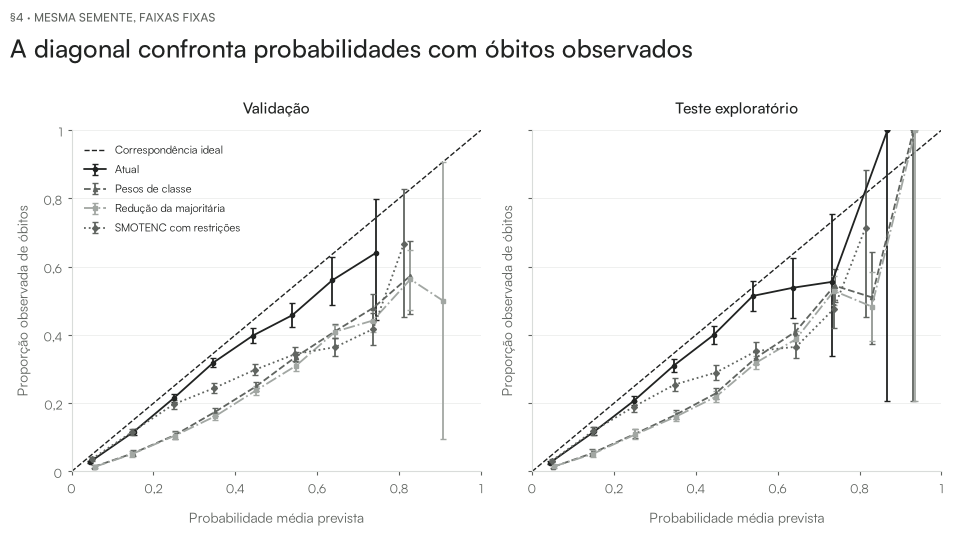

Semente exibida no gráfico: 42; todas as sementes estão na tabela.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=SP.SLOT, sharex=True, sharey=True)
for ax, split in zip(axes, JANELAS):
    ax.plot(
        [0, 1],
        [0, 1],
        color=SP.ESCURO,
        linestyle="--",
        linewidth=1,
        label="Correspondência ideal",
    )
    for method in ORDEM:
        run = next(
            r for r in E["runs"] if r["method"] == method and r["seed"] == RANDOM_STATE
        )
        rows = [b for b in run["curves"][split]["bins"] if b["n"]]
        x = np.array([b["mean_pred"] for b in rows])
        y = np.array([b["event_rate"] for b in rows])
        errors = np.array(
            [
                [b["event_rate"] - b["lo"] for b in rows],
                [b["hi"] - b["event_rate"] for b in rows],
            ]
        )
        ax.errorbar(
            x,
            y,
            yerr=errors,
            color=CORES[method],
            marker=MARCADORES[method],
            linestyle=TRACOS[method],
            markersize=3,
            linewidth=1.3,
            capsize=2,
            label=NOMES[method],
        )
    ax.set_title(JANELAS[split])
    ax.set_xlabel("Probabilidade média prevista")
    ax.set_ylabel("Proporção observada de óbitos")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes[0].legend(fontsize=8, loc="upper left")
SP.titulo(
    fig,
    "A diagonal confronta probabilidades com óbitos observados",
    "§4 · mesma semente, faixas fixas",
)
_ = SP.salvar(fig, "balanceamento_calibracao_bruta")
plt.show()
print(
    f"Semente exibida no gráfico: {SP.pt_int(RANDOM_STATE)}; todas as sementes estão na tabela."
)


**O que olhar.**

- A média prevista pode estar próxima da frequência global e ainda esconder desvios por faixa.
- AUC maior não garante probabilidades mais bem calibradas.
- Faixas com poucos registros produzem frequências mais incertas; consulte suas contagens antes de interpretar a curva.
- O diagnóstico no teste serve para descrever o resultado exploratório, não para calibrar e reavaliar sobre os mesmos rótulos.


## §5 — Diferenças pareadas e seus limites de interpretação

Cada réplica do bootstrap sorteia registros da mesma janela com reposição e
usa exatamente os mesmos índices para o candidato e a referência. O delta
é sempre **candidato menos atual**. Isso mantém o pareamento entre as
previsões sobre as mesmas fichas.

O intervalo é condicional aos modelos já ajustados e aos registros dessa
janela. Não inclui a incerteza do treino, das escolhas de configuração ou
da coleta, nem resolve dependências entre registros ou deriva temporal.
As execuções dos amostradores são apresentadas separadamente. Para o desvio
médio (`gap`), o sinal do delta indica mudança na probabilidade média; a
melhoria exige aproximação do desvio a zero, não simplesmente um delta menor.


In [9]:
comparacoes = pd.DataFrame(E["comparisons"])
comparacoes["estratégia"] = comparacoes["method"].map(NOMES)
comparacoes["direção favorável"] = comparacoes["metric"].map({
    "brier": "delta negativo", "logloss": "delta negativo", "auc": "delta positivo",
    "ap": "delta positivo", "gap": "aproximar o gap de zero; consultar valores absolutos",
})
comparacoes = comparacoes.rename(columns={"seed": "semente", "split": "conjunto", "metric": "métrica"})
print("Todas as diferenças e intervalos pareados registrados")
print(SP.tabela(comparacoes[["estratégia", "semente", "conjunto", "métrica", "delta", "ci_low", "ci_high", "direção favorável"]], 6))
print(f"Comparações registradas: {SP.pt_int(len(comparacoes))}")
print(f"Intervalos percentis: {SP.pct(1 - 2 * 0.025, 0)}; réplicas: {SP.pt_int(E['protocol']['bootstrap_repeats'])}.")
print("Referência de cada delta: mesma janela, modelo atual, semente " + SP.pt_int(RANDOM_STATE) + ".")


Todas as diferenças e intervalos pareados registrados
            estratégia semente conjunto métrica     delta    ci_low   ci_high                                    direção favorável
       Pesos de classe      42      val   brier  0,028088  0,026645  0,029622                                       delta negativo
       Pesos de classe      42      val logloss  0,068253  0,064755  0,071628                                       delta negativo
       Pesos de classe      42      val     auc -0,001527 -0,002831 -0,000229                                       delta positivo
       Pesos de classe      42      val      ap -0,003373 -0,006100 -0,000555                                       delta positivo
       Pesos de classe      42      val     gap  0,125097  0,124332  0,125912 aproximar o gap de zero; consultar valores absolutos
       Pesos de classe      42     test   brier  0,028297  0,026512  0,030071                                       delta negativo
       Pesos de classe      4

**O que olhar.**

- Para Brier e log-loss, intervalos inteiramente positivos indicam piora na comparação pareada desta janela.
- Para AUC e AP, intervalos inteiramente positivos indicam melhora na comparação pareada desta janela.
- Intervalos que cruzam o valor nulo não demonstram equivalência entre estratégias.
- Compare o tamanho do efeito, a calibração e a variação entre sementes antes de defender uma mudança de modelo.


## §6 — Síntese reproduzível: o que mudou e o que ainda falta decidir

A célula seguinte gera a síntese diretamente das métricas. As médias entre
sementes são resumos descritivos das execuções, não previsões de um ensemble.
As conclusões preservam a separação entre qualidade probabilística,
ordenação e decisões por limiar. Nenhum resultado desta exploração altera
automaticamente o modelo do curso.


In [10]:
medidas = ["brier", "logloss", "auc", "ap", "gap", "sensitivity", "specificity", "alert_rate"]
resumo = (placar.groupby(["conjunto", "método"], sort=False)[medidas]
          .agg(["mean", "min", "max"]))
resumo.columns = [f"{metric} {stat}" for metric, stat in resumo.columns]
resumo = resumo.reset_index()
resumo["estratégia"] = resumo["método"].map(NOMES)
print("Resumo completo por estratégia e janela: média e extremos das execuções")
print(SP.tabela(resumo.drop(columns="método"), 6))

for split in JANELAS:
    current = placar.loc[(placar["método"] == "atual") & (placar["conjunto"] == split)].iloc[0]
    print("\n" + JANELAS[split])
    print(f"Atual: Brier {SP.pt(current.brier, 6)}, log-loss {SP.pt(current.logloss, 6)}, "
          f"AUC {SP.pt(current.auc, 6)}, AP {SP.pt(current.ap, 6)}; "
          f"previsto médio {SP.pct(current.mean_pred, 2)}, observado {SP.pct(current.observed, 2)}.")
    for method in ORDEM[1:]:
        sub = placar.loc[(placar["método"] == method) & (placar["conjunto"] == split)]
        delta = sub[medidas].mean() - current[medidas].astype(float)
        print(f"{NOMES[method]} ({SP.pt_int(len(sub))} execução/execuções): "
              f"Δ Brier {SP.pt(delta.brier, 6, sinal=True)}, "
              f"Δ log-loss {SP.pt(delta.logloss, 6, sinal=True)}, "
              f"Δ AUC {SP.pt(delta.auc, 6, sinal=True)}, "
              f"Δ AP {SP.pt(delta.ap, 6, sinal=True)}; "
              f"gap médio {SP.pct(sub.gap.mean(), 2, sinal=True)}.")
print("\nAdoção automática de uma nova estratégia: não realizada.")
print("A interpretação deve considerar probabilidades brutas, composição do treino e avaliação temporal exploratória.")


Resumo completo por estratégia e janela: média e extremos das execuções
conjunto brier mean brier min brier max logloss mean logloss min logloss max auc mean  auc min  auc max  ap mean   ap min   ap max gap mean  gap min  gap max sensitivity mean sensitivity min sensitivity max specificity mean specificity min specificity max alert_rate mean alert_rate min alert_rate max             estratégia
     val   0,135617  0,135617  0,135617     0,420903    0,420903    0,420903 0,756427 0,756427 0,756427 0,381674 0,381674 0,381674 0,031616 0,031616 0,031616         0,102362        0,102362        0,102362         0,974305        0,974305        0,974305        0,040210       0,040210       0,040210                  Atual
    test   0,130808  0,130808  0,130808     0,409020    0,409020    0,409020 0,764448 0,764448 0,764448 0,388790 0,388790 0,388790 0,032929 0,032929 0,032929         0,110357        0,110357        0,110357         0,977343        0,977343        0,977343        0,038657       

**O que o livro diz.** A importância por permutação descrita por Molnar
mede a mudança de desempenho de um modelo fixo quando uma entrada é
embaralhada. Balancear o treino modifica o próprio modelo. Esta comparação
diagnostica estratégias sob uma receita fixa; não seleciona automaticamente
um novo preditor nem é uma variante de PFI.

A documentação do imbalanced-learn distingue SMOTENC, próprio para dados
mistos, de SMOTE aplicado indiscriminadamente às categorias. Nosso braço
acrescenta reconstrução e rejeição de propostas: seus resultados devem
ser atribuídos à estratégia restrita efetivamente implementada.

**Próximas decisões.** Definir o instante em que a previsão será usada,
avaliar a disponibilidade das variáveis nesse instante e explicitar o custo
de falsos alertas e de óbitos não detectados. Uma eventual recalibração
exige ajuste em dados separados da avaliação final. Uma nova alegação
prospectiva exige dados futuros ainda não consultados.

Fontes: [Molnar — Permutation Feature Importance](https://christophm.github.io/interpretable-ml-book/feature-importance.html) ·
[imbalanced-learn — SMOTENC](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html) ·
[scikit-learn — calibração](https://scikit-learn.org/stable/modules/calibration.html).

**Encerramento da §6.** A comparação é concluída sob a receita fixa, sem
substituir a referência do curso. Ela permanece separada do ajuste posterior
por estratégia, documentado em [COURSE_STUDY.md](../../COURSE_STUDY.md).
